# 06 · Station use vs. tract income

**Who Gets a Bluebike?** · CP 101 final project

Does station use rise with neighborhood income? Each point is one Bluebikes station in Boston. Use is total trips started there in 2024; income is the ACS median household income of the census tract the station sits in.

Run `01_clean_data.ipynb` first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CLEAN = Path("../data/clean")

station_month = pd.read_csv(
    CLEAN / "station_month.csv",
    dtype={"station_id": str, "GEOID": str},
)
tracts = pd.read_csv(
    CLEAN / "boston_tracts.csv",
    dtype={"GEOID": str},
)

usage = (
    station_month.groupby(["station_id", "GEOID", "in_boston"], dropna=False)["trips_started"]
    .sum()
    .reset_index()
)

# keep stations in Boston with median income data
stations = usage[usage["in_boston"]].merge(
    tracts[["GEOID", "median_hh_income"]],
    on="GEOID",
    how="left",
)
plot_df = stations.dropna(subset=["median_hh_income"])

print(f"{len(usage):,} stations in station_month")
print(f"{int(stations['in_boston'].sum()):,} inside Boston")
print(f"{len(plot_df):,} with a tract income estimate (plotted)")
print(f"{int(stations['median_hh_income'].isna().sum()):,} Boston stations skipped (no income estimate)")

529 stations in station_month
281 inside Boston
265 with a tract income estimate (plotted)
16 Boston stations skipped (no income estimate)


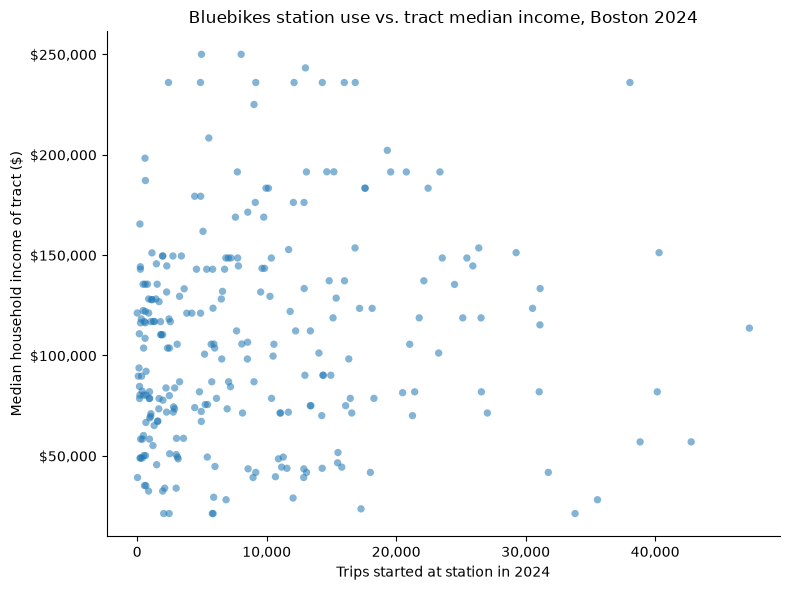

In [2]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    plot_df["trips_started"],
    plot_df["median_hh_income"],
    alpha=0.55,
    edgecolors="none",
    s=28,
)
ax.set_xlabel("Trips started at station in 2024")
ax.set_ylabel("Median household income of tract ($)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.yaxis.set_major_formatter(lambda y, _: f"${y:,.0f}")
ax.set_title("Bluebikes station use vs. tract median income, Boston 2024")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()